In [46]:
import time
import itertools
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist

D_MAX = 3       # maximum number of conditions in a subgroup
Q = 5           # return the 5 best subgroups
W = 20          # beam width for Beam Search
U = 150         # closest trajectory pairs used by BUSPaS
MIN_COV = 0.01  # subgroup must contain at least 1% of records

In [ ]:
# One row = one Store–Dept record, one column = one week.
# This index fixes the record order; every descriptor row is aligned to it.
df = pd.read_csv("final_walmart_data.csv", parse_dates=["Date"])

target_matrix = (
    df.pivot(index=["Store", "Dept"], columns="Date", values="Standardised_Weekly_Sales")
    .sort_index()
    .sort_index(axis=1)
)
print(target_matrix.head())

Y = target_matrix.to_numpy(dtype=float)   # (N records, T weeks)
record_index = target_matrix.index
first_week, last_week = target_matrix.columns.min(), target_matrix.columns.max()

print("Records N first tuple", Y.shape)
print("Target dimensions T:", Y.shape[1], f"({first_week.date()} to {last_week.date()})")
print("Per-series mean =0, std =1:", np.abs(Y.mean(1)).max().round(6), Y.std(1, ddof=1).round(6).min())

Date        2010-02-05  2010-02-12  2010-02-19  2010-02-26  2010-03-05  \
Store Dept                                                               
1     1       0.244682    2.387389    1.936427   -0.315575   -0.069555   
      2       1.308808   -0.412521    0.530942   -0.525833    0.667279   
      3       0.067705   -0.259805   -0.186820   -0.231406   -0.100459   
      4       1.020196   -0.550362   -0.046816   -0.786159    0.382856   
      5       0.703551    0.473322    0.195081   -0.013773   -0.103775   

Date        2010-03-12  2010-03-19  2010-03-26  2010-04-02  2010-04-09  ...  \
Store Dept                                                              ...   
1     1      -0.149166   -0.038225    0.377081    3.525865    2.074981  ...   
      2      -0.683050   -0.722708   -1.223464    0.391903    0.130102  ...   
      3      -0.347576   -0.476417   -0.319627   -0.228890   -0.341164  ...   
      4      -1.465686   -0.971115   -1.055067    0.288442   -0.269466  ...   
      5

In [49]:
# Rebuild descriptors from the raw weekly data so nothing is lost to the
# earlier mean/slope + quantile binning.
features = pd.read_csv("Walmart/features.csv", parse_dates=["Date"])
stores = pd.read_csv("Walmart/stores.csv")

# Use the same 143 weeks as the target (features.csv runs until 2013).
features = (
    features[features["Date"].between(first_week, last_week)]
    .sort_values(["Store", "Date"])
)

print("Weeks per store:", features.groupby("Store").size().unique())

Weeks per store: [143]


Volatility answers "how much did this store's temperature or fuel price swing around its trend". That's information the mean and slope throw away (Bart makes this point on p.39).

In [50]:
# Each weekly series becomes three per-store values:
#   mean       = level
#   slope      = linear trend per year
#   volatility = std of the residuals after removing the trend
# Bart (p.39): the mean alone loses information; adding variation keeps more.
weekly_variables = ["Temperature", "Fuel_Price", "CPI", "Unemployment"]

def summarise(values):
    y = values.to_numpy(dtype=float)
    t = np.arange(len(y))
    slope, intercept = np.polyfit(t, y, 1)
    return pd.Series({
        "mean": y.mean(),
        "slope": slope * 52,
        "volatility": (y - (slope * t + intercept)).std(),
    })

store_desc = []
for variable in weekly_variables:
    summary = features.groupby("Store")[variable].apply(summarise).unstack()
    summary.columns = [f"{variable}_{c}" for c in summary.columns]
    store_desc.append(summary)
store_desc = pd.concat(store_desc, axis=1)

# Markdowns only exist from Nov 2011. Over that period, take the average weekly
# markdown per square foot (a missing markdown is treated as no markdown).
md_cols = [f"MarkDown{i}" for i in range(1, 6)]
md_start = features.loc[features[md_cols].notna().any(axis=1), "Date"].min()
md_period = features[features["Date"] >= md_start]
md_weekly_total = md_period[md_cols].fillna(0).sum(axis=1).groupby(md_period["Store"]).mean()

store_desc = store_desc.join(stores.set_index("Store")[["Type", "Size"]])
store_desc["MarkDown_per_sqft"] = md_weekly_total / store_desc["Size"]

# IsHoliday is left out: it is the same for every store in a given week,
# so it cannot tell records apart.
store_desc.head()

,Temperature_mean,Temperature_slope,Temperature_volatility,Fuel_Price_mean,Fuel_Price_slope,Fuel_Price_volatility,CPI_mean,CPI_slope,CPI_volatility,Unemployment_mean,Unemployment_slope,Unemployment_volatility,Type,Size,MarkDown_per_sqft
Store,,,,,,,,,,,,,,,
1,68.306783,2.756073,14.031018,3.219699,0.419353,0.265514,215.996892,5.319326,0.983286,7.610420,-0.381145,0.233852,A,151315,0.135341
2,68.216364,3.012559,15.252152,3.219699,0.419353,0.265514,215.646311,5.309117,0.980281,7.623846,-0.724722,0.212375,A,202307,0.138291
3,71.434196,2.975100,12.378263,3.219699,0.419353,0.265514,219.391531,5.418174,1.012441,7.176986,-0.427478,0.288915,B,37392,0.182579
4,62.253357,4.441880,15.733049,3.216972,0.407656,0.260616,128.679669,2.248199,0.493925,5.964692,-1.767526,0.192634,A,205863,0.131116
5,69.410140,3.330514,13.926787,3.219699,0.419353,0.265514,216.565581,5.335885,0.988162,6.295406,-0.406241,0.212230,B,34875,0.232424


In [52]:
records = (
    pd.DataFrame(index=record_index).reset_index()
    .merge(store_desc.reset_index(), on="Store", how="left", validate="many_to_one")
)

# Row i of records must describe row i of Y.
assert (pd.MultiIndex.from_frame(records[["Store", "Dept"]]) == record_index).all()
assert records.notna().all().all()
print(records.shape)
print(records.head())

(2733, 17)
   Store  Dept  Temperature_mean  Temperature_slope  Temperature_volatility  \
0      1     1         68.306783           2.756073               14.031018   
1      1     2         68.306783           2.756073               14.031018   
2      1     3         68.306783           2.756073               14.031018   
3      1     4         68.306783           2.756073               14.031018   
4      1     5         68.306783           2.756073               14.031018   

   Fuel_Price_mean  Fuel_Price_slope  Fuel_Price_volatility    CPI_mean  \
0         3.219699          0.419353               0.265514  215.996892   
1         3.219699          0.419353               0.265514  215.996892   
2         3.219699          0.419353               0.265514  215.996892   
3         3.219699          0.419353               0.265514  215.996892   
4         3.219699          0.419353               0.265514  215.996892   

   CPI_slope  CPI_volatility  Unemployment_mean  Unemployment_s

In [53]:
# Bins are z-scores over all records: <-1.5, -1.5..-0.5, -0.5..0.5, 0.5..1.5, >1.5
numeric_descriptors = [c for c in store_desc.columns if c != "Type"]
labels = ["very_low", "low", "medium", "high", "very_high"]

for column in numeric_descriptors:
    z = (records[column] - records[column].mean()) / records[column].std()
    records[f"{column}_cat"] = pd.cut(
        z, bins=[-np.inf, -1.5, -0.5, 0.5, 1.5, np.inf], labels=labels
    ).astype(str)

category_columns = [f"{c}_cat" for c in numeric_descriptors]
records[category_columns].apply(lambda s: s.value_counts()).T.fillna(0).astype(int)

,high,low,medium,very_high,very_low
Temperature_mean_cat,1090,891,532,36,184
Temperature_slope_cat,324,556,1396,306,151
Temperature_volatility_cat,1063,345,1055,0,270
Fuel_Price_mean_cat,795,1435,325,178,0
Fuel_Price_slope_cat,1298,969,288,0,178
Fuel_Price_volatility_cat,969,404,971,33,356
CPI_mean_cat,1254,1349,130,0,0
CPI_slope_cat,999,1349,385,0,0
CPI_volatility_cat,999,1604,130,0,0
Unemployment_mean_cat,223,623,1578,178,131


In [54]:
descriptor_cols = ["Store", "Dept", "Type"] + category_columns

A = records[descriptor_cols].to_numpy(dtype=object)   # (N, k)

print("A (descriptors):", A.shape)   # (2733, 17)
print("Y (targets):    ", Y.shape)   # (2733, 143)

A (descriptors): (2733, 17)
Y (targets):     (2733, 143)


In [56]:
import heapq
import itertools
import time

# Parameters from Bart's real-data (stock) experiment, §6.3.1
D_MAX = 3                  # d: max conditions in a description
Q = 20                     # q: result set size
W = 50                     # w: beam width (BS only)
U = 200                    # u: number of closest pairs (BUS only)
Z = 2                      # z: mini-cluster size (BUS only)
MIN_COV = 0.01             # constraint: subgroup holds at least 1% of records
DISTANCE = "sqeuclidean"   # eq. 2.15: sum of squared differences, no square root
NU = 100                   # ν: swap-randomised runs for p-values (thesis uses 500)
SEED = 0

## Quality measure

In [57]:
# The only place the 143-dim target is used: one N x N distance matrix.
D_target = cdist(Y, Y, metric=DISTANCE)


class ClusterQuality:
    """phi = alpha / (beta + 1) * xi
    alpha = mean distance subgroup <-> complement   (eq. 4.1)
    beta  = mean distance within subgroup           (eq. 4.2)
    xi = 1: no size correction, as in all of Bart's experiments."""

    def __init__(self, D, min_cov=MIN_COV, xi=1.0):
        self.D = D
        self.N = len(D)
        self.rowsum = D.sum(axis=1)
        self.min_n = max(2, int(np.ceil(min_cov * self.N)))
        self.xi = xi
        self.cache = {}

    def satisfies_constraints(self, mask):
        return self.min_n <= mask.sum() < self.N

    def components(self, mask):
        idx = np.flatnonzero(mask)
        n, n_c = len(idx), self.N - len(idx)
        within = self.D[np.ix_(idx, idx)].sum()
        between = self.rowsum[idx].sum() - within
        return between / (n * n_c), within / (n * (n - 1))

    def __call__(self, mask):
        key = mask.tobytes()
        if key not in self.cache:
            alpha, beta = self.components(mask)
            self.cache[key] = alpha / (beta + 1) * self.xi
        return self.cache[key]

In [58]:
def mask_of(A, desc):
    mask = np.ones(len(A), dtype=bool)
    for j, v in desc:
        mask &= A[:, j] == v
    return mask


def describe_desc(desc):
    return " AND ".join(f"{descriptor_cols[j]} = {v}" for j, v in desc)


class ResultSet:
    """PriorityQueue(q) from Alg. 1 and Alg. 2: keeps the q best descriptions.
    Re-descriptions (same records, different description, §4.3.6) are stored once,
    with the shortest description. BS and BUS use the same rule, so they compare fairly."""

    def __init__(self, q, drop_redescriptions=True):
        self.q = q
        self.drop = drop_redescriptions
        self.items = {}

    def insert(self, quality, desc, mask):
        key = mask.tobytes() if self.drop else desc
        old = self.items.get(key)
        if old is not None and len(old[1]) <= len(desc):
            return
        self.items[key] = (quality, desc, mask)
        if len(self.items) > self.q:
            worst = min(self.items, key=lambda k: self.items[k][0])
            del self.items[worst]

    def sorted(self):
        return sorted(self.items.values(), key=lambda x: -x[0])

In [59]:
def refine(seed, seed_mask, A):
    """eta: add one condition on an attribute not yet used, using only the values
    still present in the seed's subgroup (§2.3). Equality conditions only, so BS
    searches the same description language that BUS can generate (§6.3.1)."""
    used = {j for j, _ in seed}
    for j in range(A.shape[1]):
        if j in used:
            continue
        for v in pd.unique(A[seed_mask, j]):
            yield tuple(sorted(seed + ((j, v),), key=lambda c: c[0]))


def beam_search(A, phi, w=W, d=D_MAX, q=Q):
    result_set = ResultSet(q)
    candidate_queue = [()]                     # start with the empty description
    seen, evaluated, tie = set(), 0, itertools.count()

    for level in range(1, d + 1):
        beam = []                              # PriorityQueue(w)
        for seed in candidate_queue:
            seed_mask = mask_of(A, seed)
            for desc in refine(seed, seed_mask, A):
                if desc in seen:
                    continue
                seen.add(desc)
                mask = mask_of(A, desc)
                if not phi.satisfies_constraints(mask):
                    continue
                quality = phi(mask)
                evaluated += 1
                result_set.insert(quality, desc, mask)
                item = (quality, next(tie), desc)
                if len(beam) < w:
                    heapq.heappush(beam, item)
                else:
                    heapq.heappushpop(beam, item)
        candidate_queue = [desc for _, _, desc in sorted(beam, reverse=True)]

    return result_set.sorted(), {"candidates": len(seen), "evaluated": evaluated}

In [60]:
_tril = {}

def find_min_indices(D, u):
    """The u smallest off-diagonal distances: the u most similar pairs of curves (eq. 4.4)."""
    N = len(D)
    if N not in _tril:
        _tril[N] = np.tril_indices(N, -1)
    rows, cols = _tril[N]
    flat = D[rows, cols]
    best = np.argpartition(flat, u)[:u]
    best = best[np.argsort(flat[best])]
    return [(int(rows[b]), int(cols[b])) for b in best]


def find_min_indices_z(D, U_pairs, z):
    """Grow pairs into mini-clusters of size z (§4.3): for every member,
    add its nearest record that is not already in the mini-cluster."""
    mini_clusters = {tuple(sorted(mc)) for mc in U_pairs}
    for _ in range(3, z + 1):
        grown = set()
        for mc in mini_clusters:
            for i in mc:
                row = D[i].copy()
                row[list(mc)] = np.inf
                grown.add(tuple(sorted(mc + (int(row.argmin()),))))
        mini_clusters = grown          # duplicates are removed by the set (prune)
    return mini_clusters


def find_possible_descriptions(mc, A, d):
    """Alg. 3: conditions shared by ALL records in the mini-cluster,
    combined into descriptions of length 1..d."""
    first = mc[0]
    condition_space = [
        (j, A[first, j])
        for j in range(A.shape[1])
        if all(A[i, j] == A[first, j] for i in mc)
    ]
    return {
        desc
        for level in range(1, d + 1)
        for desc in itertools.combinations(condition_space, level)
    }


def bottom_up_search(A, phi, u=U, z=Z, d=D_MAX, q=Q):
    result_set = ResultSet(q)
    mini_clusters = find_min_indices_z(phi.D, find_min_indices(phi.D, u), z)

    candidate_descriptions = set()             # set = only unique descriptions (step 12)
    for mc in mini_clusters:
        candidate_descriptions.update(find_possible_descriptions(mc, A, d))

    evaluated = 0
    for desc in candidate_descriptions:
        mask = mask_of(A, desc)
        if not phi.satisfies_constraints(mask):
            continue
        quality = phi(mask)
        evaluated += 1
        result_set.insert(quality, desc, mask)

    return result_set.sorted(), {
        "mini_clusters": len(mini_clusters),
        "candidates": len(candidate_descriptions),
        "evaluated": evaluated,
    }

## Experiment 

In [61]:
start = time.time()
top_bs, stats_bs = beam_search(A, ClusterQuality(D_target))
stats_bs["runtime_s"] = time.time() - start

start = time.time()
top_bus, stats_bus = bottom_up_search(A, ClusterQuality(D_target))
stats_bus["runtime_s"] = time.time() - start

print("BS: ", stats_bs)
print("BUS:", stats_bus)

BS:  {'candidates': 6179, 'evaluated': 290, 'runtime_s': 2.153430938720703}
BUS: {'mini_clusters': 200, 'candidates': 6300, 'evaluated': 3682, 'runtime_s': 2.860938549041748}


In [62]:
def swap_randomize(D, rng):
    """Shuffle the lower triangle (no diagonal), then mirror it: same distances,
    but no longer tied to the records' descriptors."""
    rows, cols = _tril[len(D)]
    D_rand = np.zeros_like(D)
    D_rand[rows, cols] = rng.permutation(D[rows, cols])
    return D_rand + D_rand.T


def distribution_of_false_discoveries(search, A, D, nu=NU, seed=SEED):
    """Run the WHOLE search nu times on randomised matrices and keep the best quality
    of each run. Because each value is the best over a full search, this also
    covers the multiple-comparison problem."""
    rng = np.random.default_rng(seed)
    dfd = []
    for _ in range(nu):
        top, _ = search(A, ClusterQuality(swap_randomize(D, rng)))
        dfd.append(top[0][0] if top else -np.inf)
    return np.array(dfd)


def empirical_p_value(quality, dfd):
    greater = (dfd > quality).sum()
    equal = (dfd == quality).sum()
    return (greater + 0.5 * equal + 1) / (len(dfd) + 1)


start = time.time()
dfd_bs = distribution_of_false_discoveries(beam_search, A, D_target)
dfd_bus = distribution_of_false_discoveries(bottom_up_search, A, D_target)
print(f"DFD done in {time.time() - start:.0f}s")
print(f"BS  DFD: max {dfd_bs.max():.3f}, mean {dfd_bs.mean():.3f}")
print(f"BUS DFD: max {dfd_bus.max():.3f}, mean {dfd_bus.mean():.3f}")

DFD done in 461s
BS  DFD: max 1.039, mean 1.025
BUS DFD: max 1.039, mean 1.010


In [63]:
def results_table(top, dfd=None):
    rows = []
    for rank, (quality, desc, mask) in enumerate(top, start=1):
        alpha, beta = ClusterQuality(D_target).components(mask)
        row = {
            "rank": rank,
            "description": describe_desc(desc),
            "quality": quality,
            "alpha": alpha,
            "beta": beta,
            "coverage_n": int(mask.sum()),
            "coverage": mask.mean(),
        }
        if dfd is not None:
            row["p_value"] = empirical_p_value(quality, dfd)
        rows.append(row)
    return pd.DataFrame(rows)


res_bs = results_table(top_bs, dfd_bs)
res_bus = results_table(top_bus, dfd_bus)

print("Beam Search"); display(res_bs)
print("Bottom-Up Search"); display(res_bus)

overlap = {m.tobytes() for _, _, m in top_bs} & {m.tobytes() for _, _, m in top_bus}
display(pd.DataFrame({
    method: {
        "subgroups evaluated": stats["evaluated"],
        "runtime (s)": round(stats["runtime_s"], 2),
        "max quality": res["quality"].max(),
        "avg quality": res["quality"].mean(),
        "max coverage": res["coverage"].max(),
        "avg coverage": res["coverage"].mean(),
        "p < 0.05": int((res["p_value"] < 0.05).sum()),
        "shared with other method": len(overlap),
    }
    for method, stats, res in [("BS", stats_bs, res_bs), ("BUS", stats_bus, res_bus)]
}))

Beam Search


,rank,description,quality,alpha,beta,coverage_n,coverage,p_value
0,1,Dept = 55,9.107625,211.534077,22.226042,37,0.013538,0.009901
1,2,Dept = 67,5.508080,233.885292,41.462219,45,0.016465,0.009901
2,3,Dept = 1,4.709371,241.793648,50.343088,45,0.016465,0.009901
3,4,Dept = 16,4.143427,285.221519,67.837108,45,0.016465,0.009901
4,5,Dept = 82,4.059298,205.256845,49.564616,45,0.016465,0.009901
5,6,Dept = 5,3.893220,215.096051,54.248887,43,0.015734,0.009901
6,7,Dept = 3,3.653530,276.998591,74.816690,45,0.016465,0.009901
7,8,Dept = 59,3.473499,223.264277,63.276480,36,0.013172,0.009901
8,9,Dept = 6,3.407010,215.705696,62.312315,39,0.014270,0.009901
9,10,Dept = 14,3.341468,207.319239,61.044356,45,0.016465,0.009901


Bottom-Up Search


,rank,description,quality,alpha,beta,coverage_n,coverage,p_value
0,1,Dept = 55,9.107625,211.534077,22.226042,37,0.013538,0.009901
1,2,Dept = 67,5.508080,233.885292,41.462219,45,0.016465,0.009901
2,3,Dept = 1,4.709371,241.793648,50.343088,45,0.016465,0.009901
3,4,Dept = 16,4.143427,285.221519,67.837108,45,0.016465,0.009901
4,5,Dept = 82,4.059298,205.256845,49.564616,45,0.016465,0.009901
5,6,Dept = 5,3.893220,215.096051,54.248887,43,0.015734,0.009901
6,7,Dept = 3,3.653530,276.998591,74.816690,45,0.016465,0.009901
7,8,Dept = 59,3.473499,223.264277,63.276480,36,0.013172,0.009901
8,9,Dept = 56,2.824258,283.362194,99.331540,37,0.013538,0.009901
9,10,Dept = 7,2.702820,205.828616,75.153286,45,0.016465,0.009901


,BS,BUS
subgroups evaluated,290.000000,3682.000000
runtime (s),2.150000,2.860000
max quality,9.107625,9.107625
avg quality,3.642486,2.844490
max coverage,0.016465,0.095134
avg coverage,0.014929,0.033772
p < 0.05,20.000000,20.000000
shared with other method,11.000000,11.000000


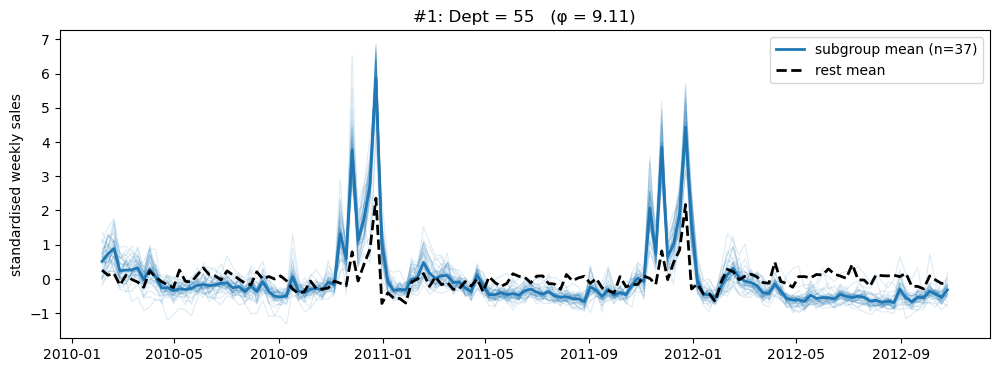

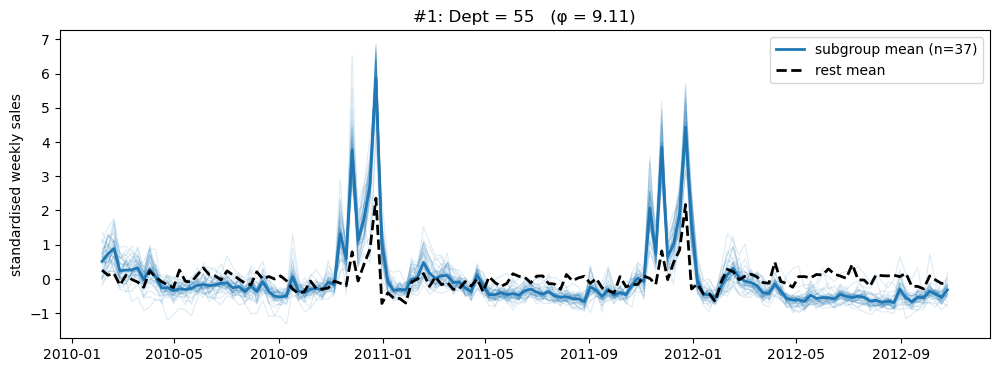

In [64]:
import matplotlib.pyplot as plt

def plot_subgroup(top, rank=1):
    quality, desc, mask = top[rank - 1]
    weeks = target_matrix.columns
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(weeks, Y[mask].T, color="tab:blue", alpha=0.15, lw=0.8)
    ax.plot(weeks, Y[mask].mean(0), color="tab:blue", lw=2, label=f"subgroup mean (n={mask.sum()})")
    ax.plot(weeks, Y[~mask].mean(0), color="black", lw=2, ls="--", label="rest mean")
    ax.set_title(f"#{rank}: {describe_desc(desc)}   (φ = {quality:.2f})")
    ax.set_ylabel("standardised weekly sales")
    ax.legend()
    plt.show()

plot_subgroup(top_bs, 1)
plot_subgroup(top_bus, 1)

In [66]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

holiday_names = {2: "Super Bowl", 9: "Labor Day", 11: "Thanksgiving", 12: "Christmas"}

train_raw = pd.read_csv("Walmart/train.csv", parse_dates=["Date"])
holidays = train_raw.loc[train_raw["IsHoliday"], ["Date"]].drop_duplicates().sort_values("Date")
holidays = holidays[holidays["Date"].between(first_week, last_week)]
holidays["name"] = holidays["Date"].dt.month.map(holiday_names)

# Raw dollars, aligned to the target rows, with gaps filled the same way as in preprocessing
sales_raw = (
    train_raw[train_raw["Weekly_Sales"] >= 0]
    .pivot(index=["Store", "Dept"], columns="Date", values="Weekly_Sales")
    .reindex(index=record_index, columns=target_matrix.columns)
    .interpolate(axis=1, limit_area="inside")
)
assert sales_raw.notna().all().all()


def mark_holidays(ax, labels=True):
    for date, name in holidays[["Date", "name"]].itertuples(index=False):
        ax.axvline(date, color="grey", ls=":", lw=1, zorder=0)
        if labels:
            ax.text(date, 1.01, name, transform=ax.get_xaxis_transform(),
                    rotation=90, va="bottom", ha="center", fontsize=8, color="grey")

In [67]:
def plot_overview(top, k=5, title=""):
    weeks = target_matrix.columns
    colors = plt.cm.tab10.colors
    fig, ax = plt.subplots(figsize=(14, 5))

    lo, med, hi = np.percentile(Y, [10, 50, 90], axis=0)
    ax.fill_between(weeks, lo, hi, color="lightgrey", label="all records, 10–90%")
    ax.plot(weeks, med, color="black", lw=1.5, label="all records, median")

    for r, (quality, desc, mask) in enumerate(top[:k]):
        ax.plot(weeks, Y[mask].mean(0), color=colors[r], lw=2,
                label=f"#{r+1} {describe_desc(desc)} (n={mask.sum()}, φ={quality:.2f})")

    mark_holidays(ax)
    ax.set_xlabel("week")
    ax.set_ylabel("standardised weekly sales")
    ax.set_title(title, pad=70)
    ax.legend(loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.show()

In [68]:
def plot_dollars(top, k=5, title=""):
    weeks = target_matrix.columns
    colors = plt.cm.tab10.colors
    total = sales_raw.sum(axis=0)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True,
                                   gridspec_kw={"height_ratios": [1, 1.3]})
    ax1.plot(weeks, total / 1e6, color="black", lw=1.5)
    ax1.set_ylabel("total weekly sales ($M)")
    ax1.set_title(title, pad=70)
    mark_holidays(ax1)

    for r, (quality, desc, mask) in enumerate(top[:k]):
        share = 100 * sales_raw[mask].sum(axis=0) / total
        ax2.plot(weeks, share, color=colors[r], lw=2, label=f"#{r+1} {describe_desc(desc)}")

    mark_holidays(ax2, labels=False)
    ax2.set_ylabel("subgroup share of total sales (%)")
    ax2.set_xlabel("week")
    ax2.legend(loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.show()

In [69]:
def plot_difference_heatmap(top, k=10, title=""):
    weeks = target_matrix.columns
    diff = np.array([Y[m].mean(0) - Y[~m].mean(0) for _, _, m in top[:k]])
    lim = np.abs(diff).max()

    fig, ax = plt.subplots(figsize=(14, 0.45 * len(diff) + 1.8))
    im = ax.imshow(diff, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim,
                   extent=[mdates.date2num(weeks[0]), mdates.date2num(weeks[-1]),
                           len(diff) - 0.5, -0.5])
    ax.xaxis_date()
    ax.set_yticks(range(len(diff)))
    ax.set_yticklabels([f"#{r+1} {describe_desc(d)}" for r, (_, d, _) in enumerate(top[:k])],
                       fontsize=8)
    mark_holidays(ax)
    fig.colorbar(im, ax=ax, label="subgroup mean − rest mean")
    ax.set_title(title, pad=70)
    plt.tight_layout()
    plt.show()

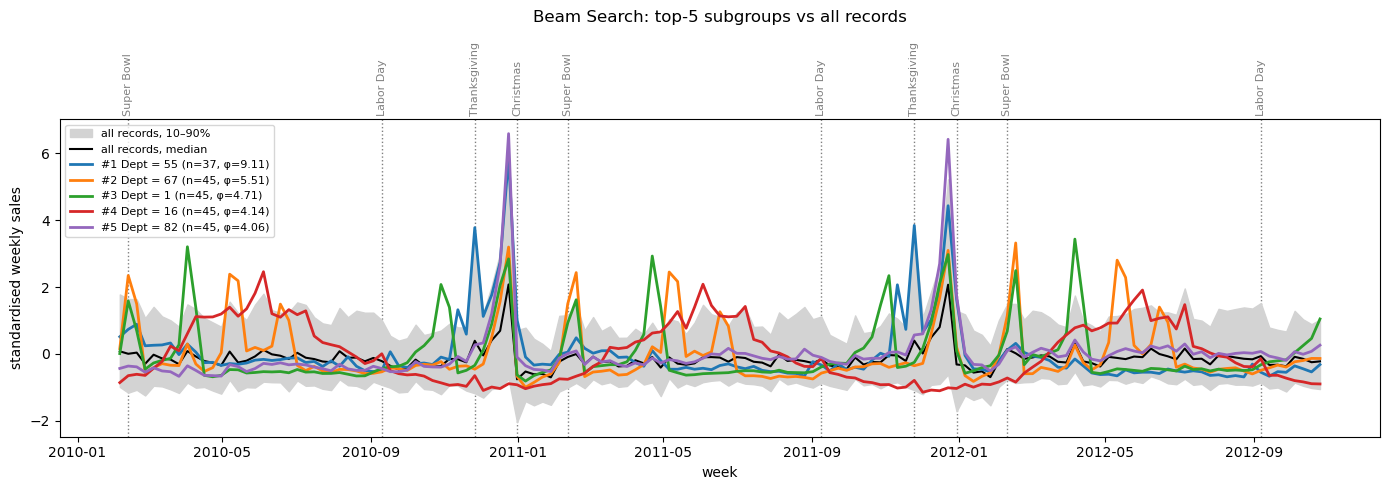

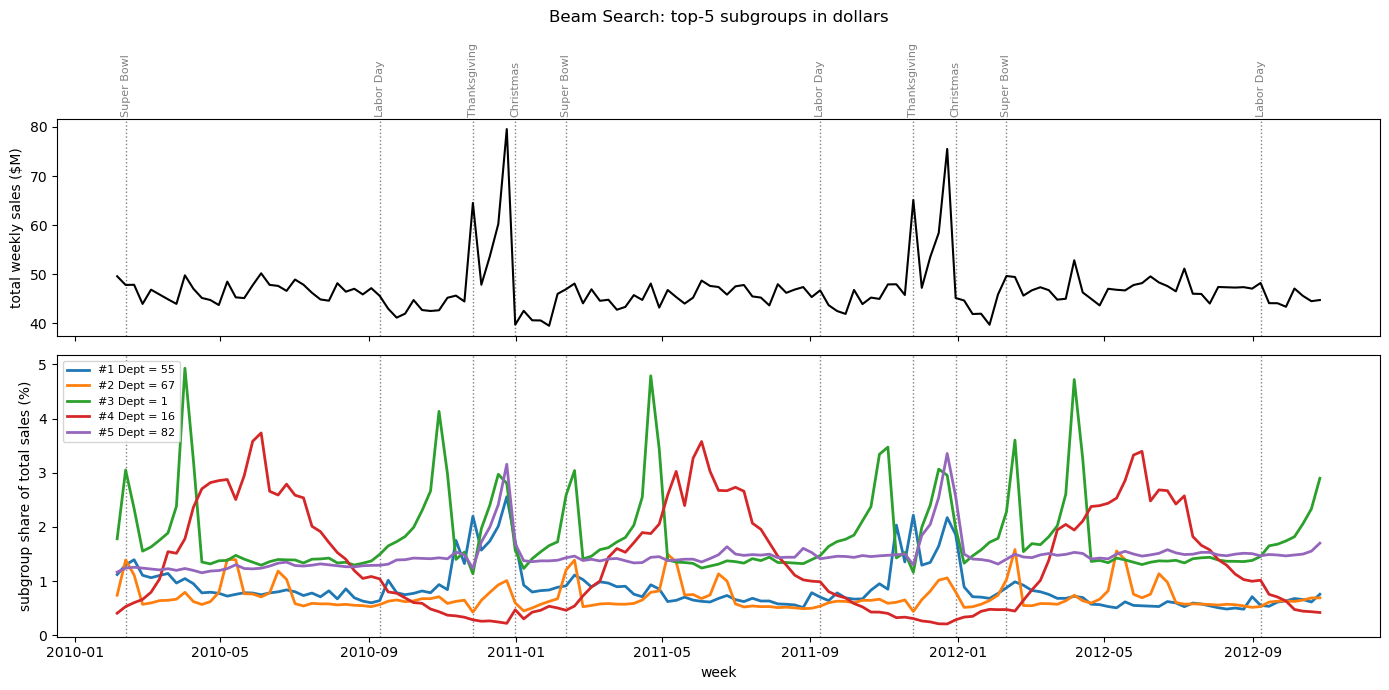

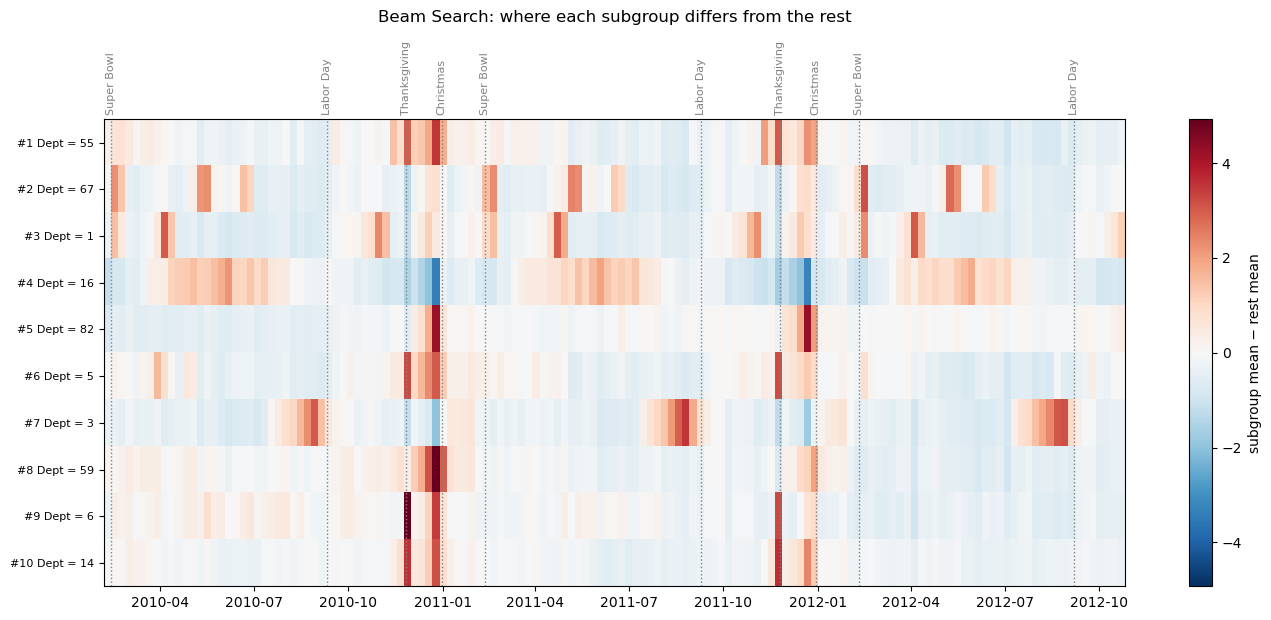

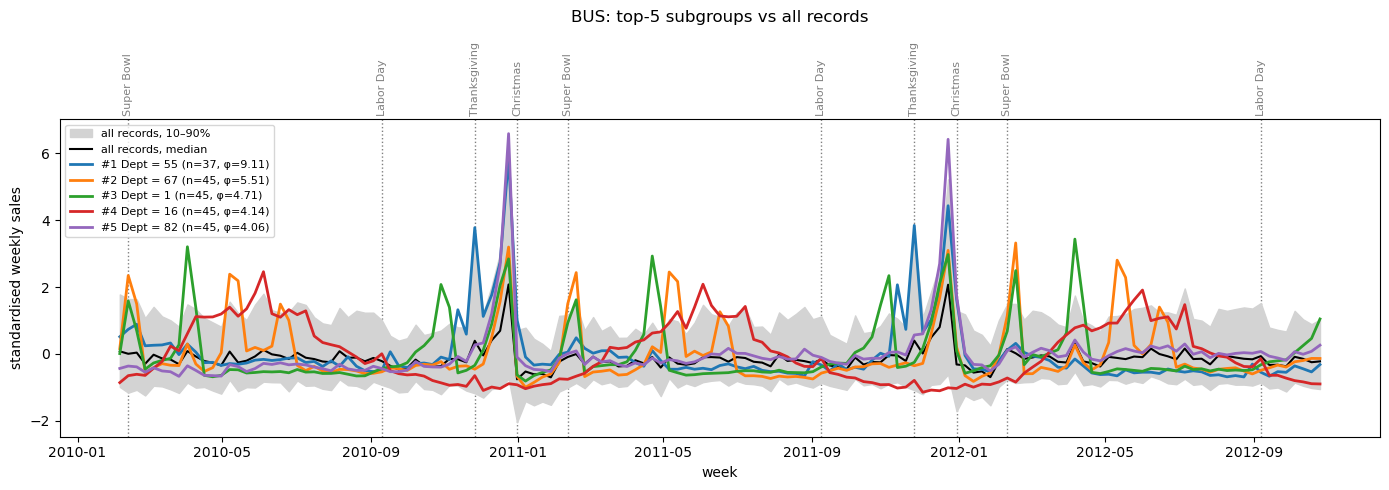

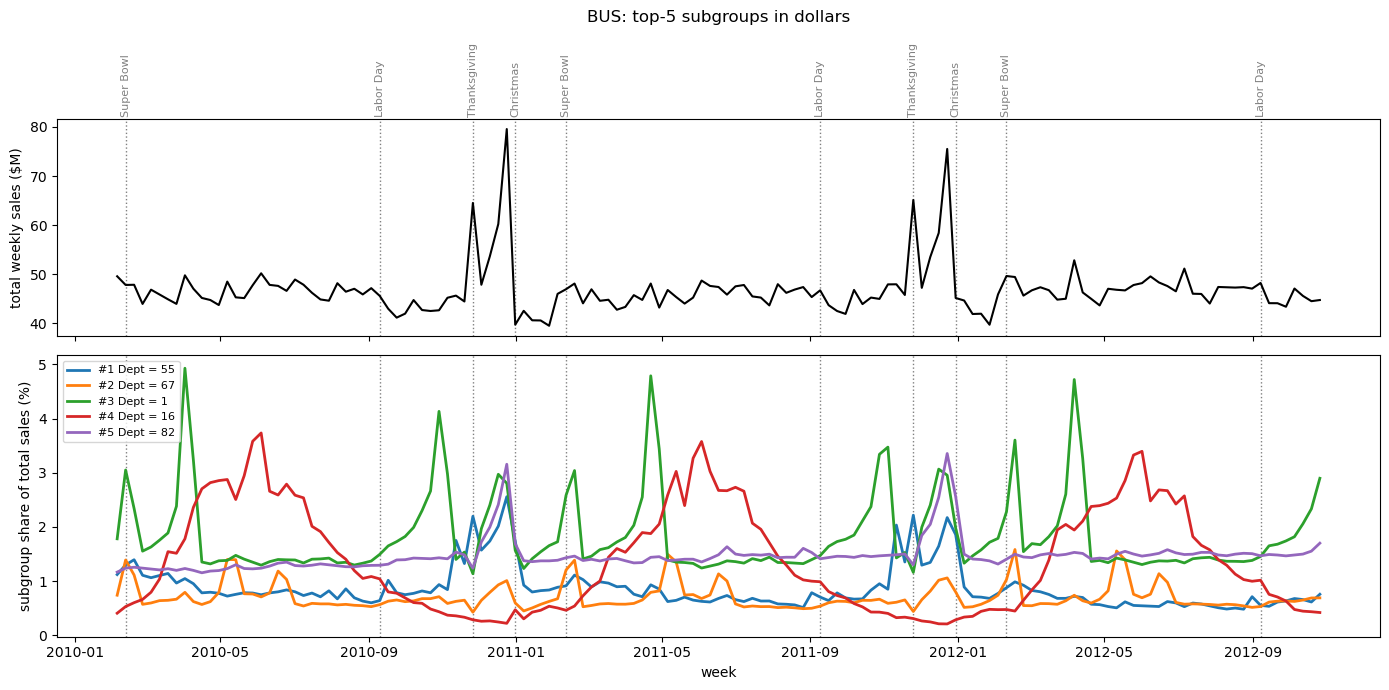

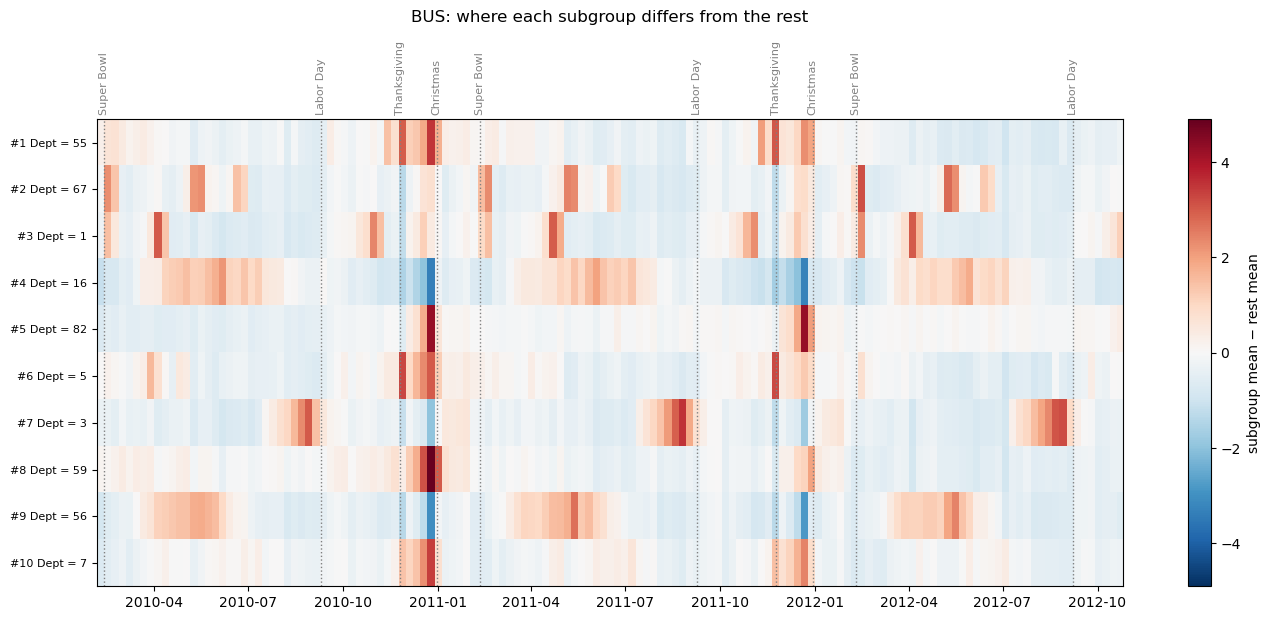

In [70]:
for name, top in [("Beam Search", top_bs), ("BUS", top_bus)]:
    plot_overview(top, k=5, title=f"{name}: top-5 subgroups vs all records")
    plot_dollars(top, k=5, title=f"{name}: top-5 subgroups in dollars")
    plot_difference_heatmap(top, k=10, title=f"{name}: where each subgroup differs from the rest")

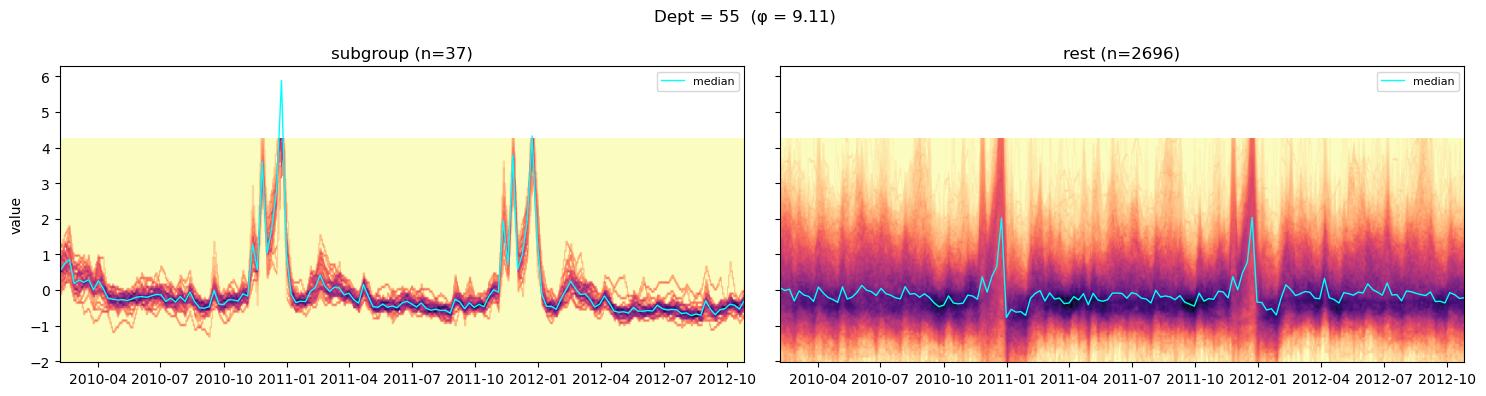

In [71]:
from matplotlib.colors import PowerNorm

# DenseLines (Moritz & Fisher, reimplemented by Bart in Appendix B):
# - Divide the y-axis into y_bins rows and the time axis into fine columns
#   (each week is split into `stretch` sub-steps).
# - Every curve "draws" its line segments into this grid. A steep segment
#   fills all the cells it crosses (this is what Bresenham's line algorithm does).
# - Each segment adds a total of 1 per column. A steep jump therefore spreads
#   thin and doesn't dominate the picture.
# - Optionally each column is normalised to sum to 1 (Bart's variant),
#   which turns the colour into "share of curves at this value".
# Dark = many curves pass here. Where the subgroup's dark band sits away from
# the rest's dark band, that is a difference you'd miss in a mess of lines.

def dense_lines(Y_sub, lo, hi, y_bins=100, stretch=4, column_normalise=True):
    n, T = Y_sub.shape
    x_fine = np.linspace(0, T - 1, (T - 1) * stretch + 1)
    Y_fine = np.stack([np.interp(x_fine, np.arange(T), y) for y in Y_sub])
    rows = np.floor((Y_fine - lo) / (hi - lo) * y_bins).astype(int)

    # each segment covers the rows between its two endpoints
    r_min = np.minimum(rows[:, :-1], rows[:, 1:])
    r_max = np.maximum(rows[:, :-1], rows[:, 1:])
    weight = 1.0 / (r_max - r_min + 1)                 # one segment = 1 unit of ink
    weight[(r_max < 0) | (r_min >= y_bins)] = 0.0      # segment entirely off the plot
    r_min, r_max = np.clip(r_min, 0, y_bins - 1), np.clip(r_max, 0, y_bins - 1)

    # add ink to rows r_min..r_max with a difference array, then cumsum
    cols = np.broadcast_to(np.arange(r_min.shape[1]), r_min.shape)
    diff = np.zeros((y_bins + 1, r_min.shape[1]))
    np.add.at(diff, (r_min.ravel(), cols.ravel()), weight.ravel())
    np.add.at(diff, (r_max.ravel() + 1, cols.ravel()), -weight.ravel())
    M = np.cumsum(diff, axis=0)[:-1]

    if column_normalise:
        M = M / np.maximum(M.sum(axis=0, keepdims=True), 1e-12)
    return M


def plot_dense_lines(Y_all, mask, title="", y_bins=100, stretch=4, clip=(0.5, 99.5)):
    """Subgroup on the left, everyone else on the right, same y-scale
    (like Bart's Fig. 6.8 vs Fig. 6.9). The cyan line is the median curve."""
    weeks = target_matrix.columns
    lo, hi = np.percentile(Y_all, clip)   # ignore the most extreme 1% so the scale isn't wasted on spikes
    extent = [mdates.date2num(weeks[0]), mdates.date2num(weeks[-1]), lo, hi]

    fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
    for ax, (label, Y_g) in zip(axes, [("subgroup", Y_all[mask]), ("rest", Y_all[~mask])]):
        M = dense_lines(Y_g, lo, hi, y_bins, stretch)
        ax.imshow(M, origin="lower", aspect="auto", extent=extent,
                  cmap="magma_r", norm=PowerNorm(0.5))
        ax.plot(weeks, np.median(Y_g, axis=0), color="cyan", lw=1, label="median")
        ax.xaxis_date()
        ax.set_title(f"{label} (n={len(Y_g)})")
        ax.legend(loc="upper right", fontsize=8)
    axes[0].set_ylabel("value")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


quality, desc, mask = top_bs[0]
plot_dense_lines(Y, mask, f"{describe_desc(desc)}  (φ = {quality:.2f})")

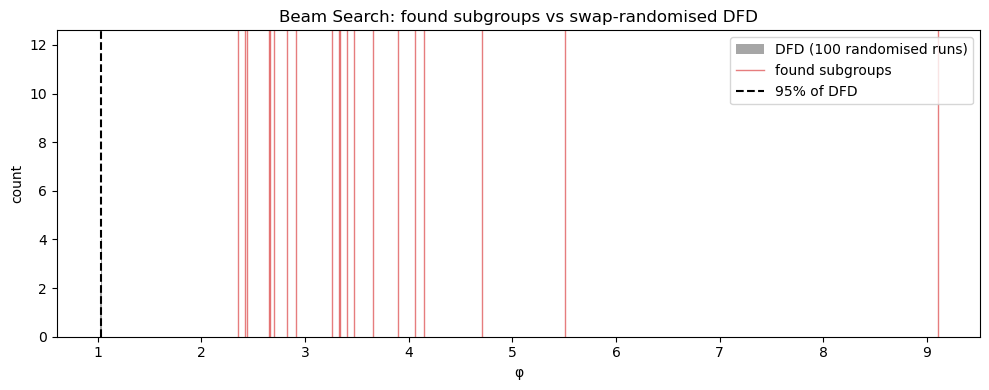

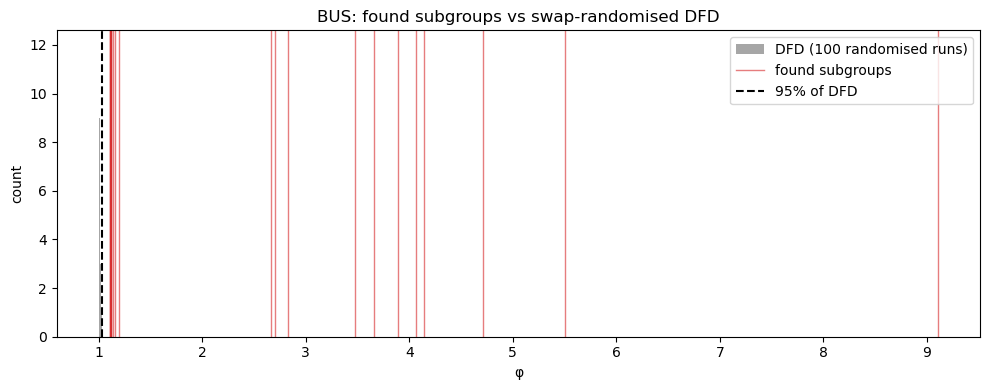

In [72]:
def plot_dfd(dfd, top, title=""):
    """Grey histogram: the best φ in each randomised run, i.e. the best you get
    when the descriptors mean nothing.
    Red lines: the subgroups actually found.
    Dashed line: the 95% point of the DFD. Bart notes this can be reused as a
    minimum-quality threshold for alpha = 0.05."""
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(dfd, bins=30, color="grey", alpha=0.7, label=f"DFD ({len(dfd)} randomised runs)")
    for i, (quality, _, _) in enumerate(top):
        ax.axvline(quality, color="tab:red", lw=1, alpha=0.6,
                   label="found subgroups" if i == 0 else None)
    ax.axvline(np.quantile(dfd, 0.95), color="black", ls="--", label="95% of DFD")
    ax.set_xlabel("φ")
    ax.set_ylabel("count")
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.show()


plot_dfd(dfd_bs, top_bs, "Beam Search: found subgroups vs swap-randomised DFD")
plot_dfd(dfd_bus, top_bus, "BUS: found subgroups vs swap-randomised DFD")

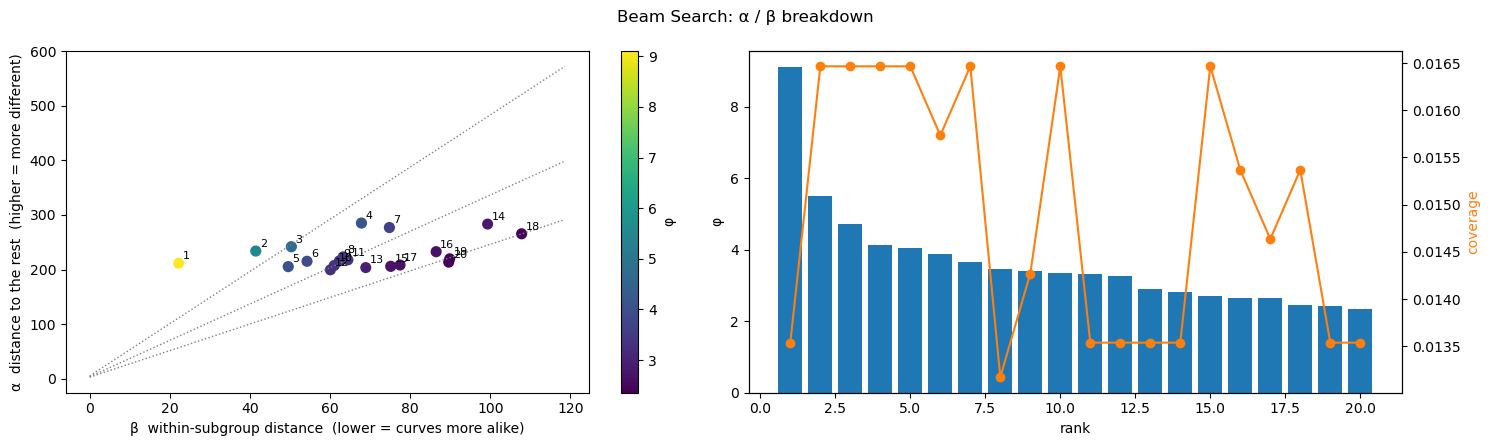

#1: Dept = 55
#2: Dept = 67
#3: Dept = 1
#4: Dept = 16
#5: Dept = 82
#6: Dept = 5
#7: Dept = 3
#8: Dept = 59
#9: Dept = 6
#10: Dept = 14
#11: Dept = 27
#12: Dept = 23
#13: Dept = 29
#14: Dept = 56
#15: Dept = 7
#16: Dept = 72
#17: Dept = 32
#18: Dept = 28
#19: Dept = 44
#20: Dept = 33


In [73]:
def plot_alpha_beta(top, phi, describe=describe_desc, title=""):
    """Left: each result as a point (β, α). Bottom-right means alike inside AND different
    from the rest. Point size = coverage. Dotted lines are equal-φ curves
    alpha = phi * (beta + 1), so you can see whether a subgroup scores high because
    it's tight (low β) or because it's far from everyone (high α).
    Right: φ by rank (bars) with coverage (orange)."""
    comps = [phi.components(m) for _, _, m in top]
    alpha = np.array([a for a, _ in comps])
    beta = np.array([b for _, b in comps])
    quality = np.array([q for q, _, _ in top])
    coverage = np.array([m.mean() for _, _, m in top])
    ranks = np.arange(1, len(top) + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
    sc = ax1.scatter(beta, alpha, c=quality, cmap="viridis", s=40 + 600 * coverage)
    for r, b, a in zip(ranks, beta, alpha):
        ax1.annotate(str(r), (b, a), xytext=(3, 3), textcoords="offset points", fontsize=8)
    b_grid = np.linspace(0, beta.max() * 1.1, 50)
    for level in np.quantile(quality, [0.1, 0.5, 0.9]):
        ax1.plot(b_grid, level * (b_grid + 1), color="grey", ls=":", lw=1)
    ax1.set_xlabel("β  within-subgroup distance  (lower = curves more alike)")
    ax1.set_ylabel("α  distance to the rest  (higher = more different)")
    fig.colorbar(sc, ax=ax1, label="φ")

    ax2.bar(ranks, quality, color="tab:blue")
    ax2.set_xlabel("rank")
    ax2.set_ylabel("φ")
    ax2b = ax2.twinx()
    ax2b.plot(ranks, coverage, color="tab:orange", marker="o")
    ax2b.set_ylabel("coverage", color="tab:orange")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    print("\n".join(f"#{r}: {describe(d)}" for r, (_, d, _) in zip(ranks, top)))


plot_alpha_beta(top_bs, ClusterQuality(D_target), title="Beam Search: α / β breakdown")

## Local subgroups: compare each record with its peers, not with everyone
Global φ rewards the obvious: a department with a Christmas spike is unlike everyone else.
Following Local Subgroup Discovery (Konijn et al.), we judge a subgroup against a
**reference group of peers**: the same department in the other stores.

1. **Store and Dept are only row identifiers.** They are removed from the descriptor space,
   so descriptions can only use store attributes (climate, economy, size, markdowns).
2. **Option A, peer-residual target:** subtract each department's chain-wide curve from every record.
   What's left is "how this store's department differs from that department elsewhere".
   The Christmas spike that every Dept 55 shares cancels out. φ itself is unchanged.
3. **Option B, peer reference-group quality:** keep the target and change φ instead.
   α and β only compare records **of the same department**.
   This is Konijn's quality "measured inside the reference group", applied to φ_cluster.
4. **Spike-robust distance and coverage:** absolute distance (Bart eq. 3.16) so one huge week
   can't dominate, a higher minimum coverage, and optional size correction ξ (Bart eq. 2.2–2.3).
5. **The right null model:** descriptors are store-level, so significance is tested by
   shuffling descriptors **between stores**, not by swap-randomising distances.

In [74]:
# Store and Dept identify the row; they are not allowed in descriptions.
# Every remaining descriptor is a store attribute, so every subgroup is
# "all departments of the stores that match the description".
local_descriptor_cols = ["Type"] + category_columns
A_local = records[local_descriptor_cols].to_numpy(dtype=object)

dept_all = records["Dept"].to_numpy()
store_all = records["Store"].to_numpy()

def describe_local(desc):
    return " AND ".join(f"{local_descriptor_cols[j]} = {v}" for j, v in desc)

print("Local descriptors:", len(local_descriptor_cols))

Local descriptors: 15


In [75]:
# Peer profile = the average standardised curve of the SAME department in the OTHER stores
# (leave-one-out, so a record isn't compared with itself).
# Residual = record - peer profile.
#   0        -> this store's dept behaves exactly like that dept elsewhere
#   positive -> this week it sold relatively more than its peers did
# Shared patterns (Christmas, back-to-school) are in the peer profile, so they cancel.
# What survives is local: e.g. one store growing faster than its peers,
# or a regional event.
MIN_PEERS = 5   # a department needs at least 5 stores for a meaningful peer profile

peer_count = records.groupby("Dept")["Dept"].transform("size").to_numpy()
dept_sum = pd.DataFrame(Y).groupby(dept_all).transform("sum").to_numpy()
Y_peer_profile = (dept_sum - Y) / np.maximum(peer_count - 1, 1)[:, None]

keep = peer_count >= MIN_PEERS
Y_resid = (Y - Y_peer_profile)[keep]
A_resid = A_local[keep]
store_resid = store_all[keep]

print(f"Kept {keep.sum()} of {len(keep)} records (dropped departments with < {MIN_PEERS} stores)")
print(f"Residual std: {Y_resid.std():.2f}  (the original target has std 1)")

Kept 2732 of 2733 records (dropped departments with < 5 stores)
Residual std: 0.70  (the original target has std 1)


In [76]:
# Distance (Bart §3.5):
#   "sqeuclidean" (eq. 2.15): squares each weekly difference, so ONE big spike dominates.
#   "cityblock"   (eq. 3.16): absolute differences, so many small consistent
#                             differences can outweigh one spike. Use this for subtle patterns.
LOCAL_DISTANCE = "cityblock"

# Coverage: every store has ~60 departments, so 5% (~137 records) means at least 2–3 stores.
# This stops a single odd store from being reported as a "pattern".
MIN_COV_LOCAL = 0.05

# Size correction xi (Bart eq. 2.1–2.3). Without it, phi prefers the smallest allowed groups.
def xi_none(n, N):
    return 1.0

def xi_entropy(n, N):        # eq. 2.2: penalises very small AND very large groups
    p = n / N
    return -p * np.log(p) - (1 - p) * np.log(1 - p)

def xi_sqrt(n, N):           # eq. 2.3 with tau = 2: penalises small groups only
    return np.sqrt(n / N)

XI = xi_none


class LocalClusterQuality(ClusterQuality):
    """Same phi = alpha / (beta + 1) as before, times a size correction xi(n, N)."""

    def __init__(self, D, min_cov=MIN_COV_LOCAL, xi=XI):
        super().__init__(D, min_cov)
        self.xi_fn = xi

    def __call__(self, mask):
        key = mask.tobytes()
        if key not in self.cache:
            alpha, beta = self.components(mask)
            self.cache[key] = alpha / (beta + 1) * self.xi_fn(mask.sum(), self.N)
        return self.cache[key]


D_resid = cdist(Y_resid, Y_resid, metric=LOCAL_DISTANCE)

In [77]:
class PeerQuality:
    """phi_cluster computed only inside the reference group of peers (Konijn's LSD idea).
    Peers = records of the SAME department.
      alpha = mean distance from each member to the NON-members of its own department
              ("does Dept 55 in these stores differ from Dept 55 in the other stores?")
      beta  = mean distance between members of the same department
              ("does Dept 55 behave alike across the stores in the subgroup?")
    Pairs across different departments are ignored, so a department's own shape
    (e.g. a Christmas spike) can never make a subgroup look exceptional.
    No residualising is needed; the original standardised target is used."""

    def __init__(self, D, groups, min_cov=MIN_COV_LOCAL, xi=XI):
        same = groups[:, None] == groups[None, :]
        np.fill_diagonal(same, False)
        self.same = same
        self.D_peer = np.where(same, D, 0.0)
        # BUS reads phi.D to find its closest pairs; inf makes sure it only pairs peers
        self.D = np.where(same, D, np.inf)
        self.rowsum = self.D_peer.sum(axis=1)
        self.rowcount = same.sum(axis=1)
        self.N = len(D)
        self.min_n = max(2, int(np.ceil(min_cov * self.N)))
        self.xi_fn = xi
        self.cache = {}

    def components(self, mask):
        idx = np.flatnonzero(mask)
        block = np.ix_(idx, idx)
        within, within_pairs = self.D_peer[block].sum(), self.same[block].sum()
        between = self.rowsum[idx].sum() - within
        between_pairs = self.rowcount[idx].sum() - within_pairs
        if within_pairs == 0 or between_pairs == 0:
            return None, None      # no peers inside or outside: can't be judged locally
        return between / between_pairs, within / within_pairs

    def satisfies_constraints(self, mask):
        return self.min_n <= mask.sum() < self.N and self(mask) is not None

    def __call__(self, mask):
        key = mask.tobytes()
        if key not in self.cache:
            alpha, beta = self.components(mask)
            self.cache[key] = None if alpha is None else alpha / (beta + 1) * self.xi_fn(mask.sum(), self.N)
        return self.cache[key]


D_peer_target = cdist(Y, Y, metric=LOCAL_DISTANCE)

In [78]:
local_setups = {
    "A: peer-residual target": (A_resid, store_resid, Y_resid, lambda: LocalClusterQuality(D_resid)),
    "B: peer reference group": (A_local, store_all, Y, lambda: PeerQuality(D_peer_target, dept_all)),
}

local_runs = {}
for setup, (A_sub, stores_sub, Y_sub, make_phi) in local_setups.items():
    for method, search in [("BS", beam_search), ("BUS", bottom_up_search)]:
        phi = make_phi()
        start = time.time()
        top, stats = search(A_sub, phi)
        stats["runtime_s"] = round(time.time() - start, 1)
        local_runs[(setup, method)] = (top, stats, phi)
        print(f"{setup:26s} {method:3s} {stats}")


def local_results_table(top, phi, stores_sub, dfd=None):
    rows = []
    for rank, (quality, desc, mask) in enumerate(top, start=1):
        alpha, beta = phi.components(mask)
        row = {
            "rank": rank,
            "description": describe_local(desc),
            "quality": quality,
            "alpha": alpha,
            "beta": beta,
            "coverage_n": int(mask.sum()),
            "n_stores": len(np.unique(stores_sub[mask])),   # how many stores does the pattern span?
        }
        if dfd is not None:
            row["p_value"] = empirical_p_value(quality, dfd)
        rows.append(row)
    return pd.DataFrame(rows)


for (setup, method), (top, stats, phi) in local_runs.items():
    print(f"\n{setup} | {method}")
    display(local_results_table(top, phi, local_setups[setup][1]).head(10))

A: peer-residual target    BS  {'candidates': 2259, 'evaluated': 1111, 'runtime_s': 2.7}
A: peer-residual target    BUS {'mini_clusters': 200, 'candidates': 3737, 'evaluated': 2671, 'runtime_s': 3.2}
B: peer reference group    BS  {'candidates': 2227, 'evaluated': 1122, 'runtime_s': 3.1}
B: peer reference group    BUS {'mini_clusters': 200, 'candidates': 3403, 'evaluated': 2631, 'runtime_s': 3.8}

A: peer-residual target | BS


,rank,description,quality,alpha,beta,coverage_n,n_stores
0,1,Type = A AND Temperature_mean_cat = low AND Un...,1.172263,98.902008,83.368462,138,2
1,2,Temperature_volatility_cat = medium AND Unempl...,1.156489,101.661527,86.905318,137,2
2,3,Type = A AND Temperature_mean_cat = low AND Fu...,1.148747,100.006074,86.056653,207,3
3,4,Unemployment_slope_cat = low AND Size_cat = high,1.142211,100.596378,87.071603,137,2
4,5,CPI_volatility_cat = low AND Unemployment_mean...,1.140027,100.342368,87.017527,208,3
5,6,Temperature_slope_cat = low AND MarkDown_per_s...,1.138070,98.955086,85.949928,137,2
6,7,Temperature_volatility_cat = high AND Fuel_Pri...,1.135792,98.111804,85.381841,137,2
7,8,Fuel_Price_mean_cat = low AND CPI_volatility_c...,1.130418,100.930017,88.285609,277,4
8,9,Type = A AND Temperature_mean_cat = low AND Fu...,1.129739,100.483083,87.943650,202,3
9,10,Type = A AND Temperature_mean_cat = low AND Un...,1.129367,101.033785,88.460571,202,3



A: peer-residual target | BUS


,rank,description,quality,alpha,beta,coverage_n,n_stores
0,1,Fuel_Price_mean_cat = low AND Unemployment_vol...,1.148747,100.006074,86.056653,207,3
1,2,Unemployment_slope_cat = low AND Size_cat = high,1.142211,100.596378,87.071603,137,2
2,3,Temperature_slope_cat = low AND MarkDown_per_s...,1.138070,98.955086,85.949928,137,2
3,4,Fuel_Price_mean_cat = low AND CPI_volatility_c...,1.130418,100.930017,88.285609,277,4
4,5,Type = A AND Temperature_mean_cat = low AND Un...,1.129367,101.033785,88.460571,202,3
5,6,CPI_volatility_cat = low AND Unemployment_vola...,1.123046,100.440026,88.435342,275,4
6,7,Type = A AND Temperature_volatility_cat = high...,1.122892,100.887382,88.845997,199,3
7,8,CPI_mean_cat = low AND Unemployment_volatility...,1.122516,98.728284,86.952638,139,2
8,9,Type = A AND Temperature_mean_cat = low AND Un...,1.122245,100.794685,88.815209,341,5
9,10,Type = A AND Unemployment_slope_cat = medium A...,1.121927,101.622298,89.578324,267,4



B: peer reference group | BS


,rank,description,quality,alpha,beta,coverage_n,n_stores
0,1,Temperature_slope_cat = low AND MarkDown_per_s...,1.387634,92.349399,65.551703,137,2
1,2,Type = A AND Temperature_volatility_cat = high...,1.366867,94.576838,68.192439,199,3
2,3,Fuel_Price_mean_cat = high AND Fuel_Price_vola...,1.357493,96.062138,69.764379,264,4
3,4,Temperature_volatility_cat = high AND Fuel_Pri...,1.354052,95.748984,69.712906,196,3
4,5,Type = A AND Temperature_mean_cat = low AND Fu...,1.341742,93.871488,68.962414,202,3
5,6,Fuel_Price_volatility_cat = medium AND MarkDow...,1.332508,94.642582,70.025879,194,3
6,7,Type = A AND Fuel_Price_mean_cat = high AND Fu...,1.311797,96.772255,72.770767,335,5
7,8,Type = A AND Temperature_volatility_cat = high...,1.304445,93.968774,71.037387,268,4
8,9,Temperature_mean_cat = low AND Fuel_Price_mean...,1.303858,94.952724,71.824460,199,3
9,10,Temperature_slope_cat = high AND Fuel_Price_vo...,1.303565,94.291427,71.333482,196,3



B: peer reference group | BUS


,rank,description,quality,alpha,beta,coverage_n,n_stores
0,1,Temperature_slope_cat = low AND MarkDown_per_s...,1.387634,92.349399,65.551703,137,2
1,2,Type = A AND Temperature_volatility_cat = high...,1.366867,94.576838,68.192439,199,3
2,3,Fuel_Price_mean_cat = high AND Fuel_Price_vola...,1.357493,96.062138,69.764379,264,4
3,4,Temperature_volatility_cat = high AND Fuel_Pri...,1.354052,95.748984,69.712906,196,3
4,5,Fuel_Price_mean_cat = high AND MarkDown_per_sq...,1.332508,94.642582,70.025879,194,3
5,6,Type = A AND Fuel_Price_volatility_cat = mediu...,1.311797,96.772255,72.770767,335,5
6,7,Type = A AND Temperature_volatility_cat = high...,1.304445,93.968774,71.037387,268,4
7,8,Temperature_mean_cat = low AND Fuel_Price_vola...,1.303858,94.952724,71.824460,199,3
8,9,Temperature_slope_cat = high AND CPI_slope_cat...,1.303565,94.291427,71.333482,196,3
9,10,Type = A AND Unemployment_mean_cat = low AND U...,1.299644,91.768920,69.610819,138,2


A: peer-residual target | BS: DFD done in 154s


,rank,description,quality,alpha,beta,coverage_n,n_stores,p_value
0,1,Type = A AND Temperature_mean_cat = low AND Un...,1.172263,98.902008,83.368462,138,2,0.084158
1,2,Temperature_volatility_cat = medium AND Unempl...,1.156489,101.661527,86.905318,137,2,0.237624
2,3,Type = A AND Temperature_mean_cat = low AND Fu...,1.148747,100.006074,86.056653,207,3,0.425743
3,4,Unemployment_slope_cat = low AND Size_cat = high,1.142211,100.596378,87.071603,137,2,0.658416
4,5,CPI_volatility_cat = low AND Unemployment_mean...,1.140027,100.342368,87.017527,208,3,0.673267
5,6,Temperature_slope_cat = low AND MarkDown_per_s...,1.138070,98.955086,85.949928,137,2,0.727723
6,7,Temperature_volatility_cat = high AND Fuel_Pri...,1.135792,98.111804,85.381841,137,2,0.836634
7,8,Fuel_Price_mean_cat = low AND CPI_volatility_c...,1.130418,100.930017,88.285609,277,4,0.910891
8,9,Type = A AND Temperature_mean_cat = low AND Fu...,1.129739,100.483083,87.943650,202,3,0.910891
9,10,Type = A AND Temperature_mean_cat = low AND Un...,1.129367,101.033785,88.460571,202,3,0.910891


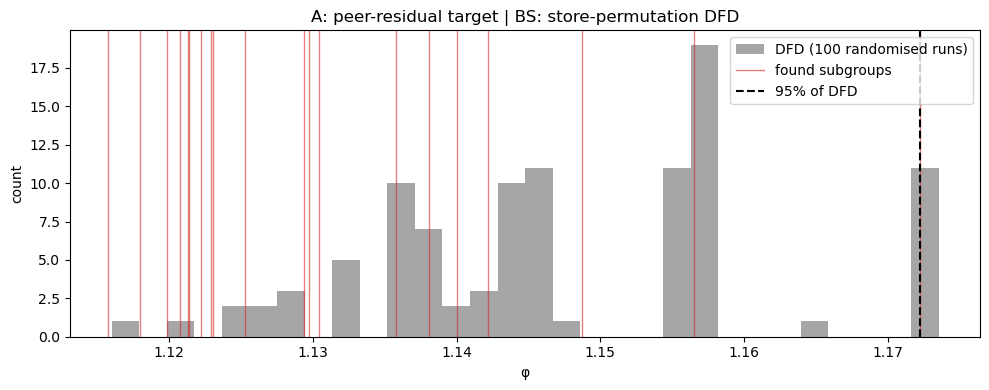

A: peer-residual target | BUS: DFD done in 208s


,rank,description,quality,alpha,beta,coverage_n,n_stores,p_value
0,1,Fuel_Price_mean_cat = low AND Unemployment_vol...,1.148747,100.006074,86.056653,207,3,0.237624
1,2,Unemployment_slope_cat = low AND Size_cat = high,1.142211,100.596378,87.071603,137,2,0.569307
2,3,Temperature_slope_cat = low AND MarkDown_per_s...,1.138070,98.955086,85.949928,137,2,0.638614
3,4,Fuel_Price_mean_cat = low AND CPI_volatility_c...,1.130418,100.930017,88.285609,277,4,0.811881
4,5,Type = A AND Temperature_mean_cat = low AND Un...,1.129367,101.033785,88.460571,202,3,0.826733
5,6,CPI_volatility_cat = low AND Unemployment_vola...,1.123046,100.440026,88.435342,275,4,0.930693
6,7,Type = A AND Temperature_volatility_cat = high...,1.122892,100.887382,88.845997,199,3,0.930693
7,8,CPI_mean_cat = low AND Unemployment_volatility...,1.122516,98.728284,86.952638,139,2,0.940594
8,9,Type = A AND Temperature_mean_cat = low AND Un...,1.122245,100.794685,88.815209,341,5,0.950495
9,10,Type = A AND Unemployment_slope_cat = medium A...,1.121927,101.622298,89.578324,267,4,0.950495


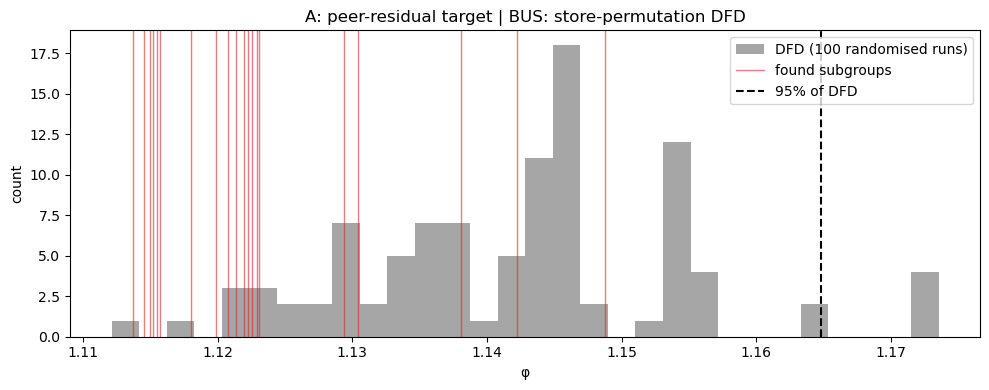

B: peer reference group | BS: DFD done in 217s


,rank,description,quality,alpha,beta,coverage_n,n_stores,p_value
0,1,Temperature_slope_cat = low AND MarkDown_per_s...,1.387634,92.349399,65.551703,137,2,0.128713
1,2,Type = A AND Temperature_volatility_cat = high...,1.366867,94.576838,68.192439,199,3,0.217822
2,3,Fuel_Price_mean_cat = high AND Fuel_Price_vola...,1.357493,96.062138,69.764379,264,4,0.217822
3,4,Temperature_volatility_cat = high AND Fuel_Pri...,1.354052,95.748984,69.712906,196,3,0.217822
4,5,Type = A AND Temperature_mean_cat = low AND Fu...,1.341742,93.871488,68.962414,202,3,0.217822
5,6,Fuel_Price_volatility_cat = medium AND MarkDow...,1.332508,94.642582,70.025879,194,3,0.232673
6,7,Type = A AND Fuel_Price_mean_cat = high AND Fu...,1.311797,96.772255,72.770767,335,5,0.257426
7,8,Type = A AND Temperature_volatility_cat = high...,1.304445,93.968774,71.037387,268,4,0.346535
8,9,Temperature_mean_cat = low AND Fuel_Price_mean...,1.303858,94.952724,71.824460,199,3,0.356436
9,10,Temperature_slope_cat = high AND Fuel_Price_vo...,1.303565,94.291427,71.333482,196,3,0.376238


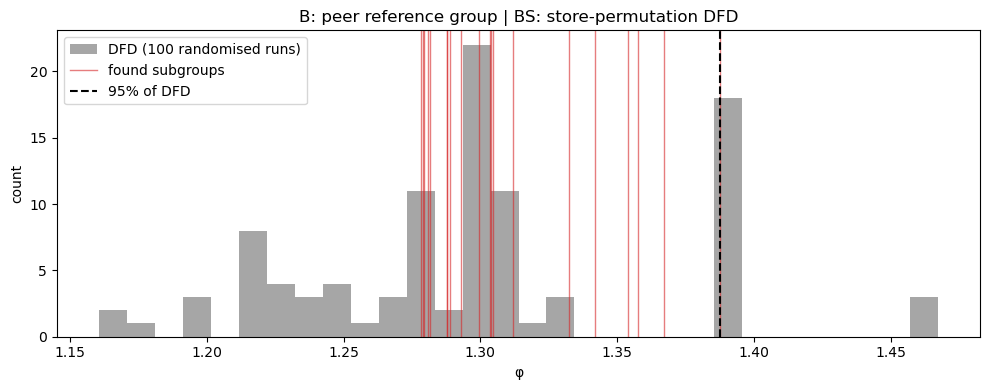

B: peer reference group | BUS: DFD done in 298s


,rank,description,quality,alpha,beta,coverage_n,n_stores,p_value
0,1,Temperature_slope_cat = low AND MarkDown_per_s...,1.387634,92.349399,65.551703,137,2,0.133663
1,2,Type = A AND Temperature_volatility_cat = high...,1.366867,94.576838,68.192439,199,3,0.227723
2,3,Fuel_Price_mean_cat = high AND Fuel_Price_vola...,1.357493,96.062138,69.764379,264,4,0.227723
3,4,Temperature_volatility_cat = high AND Fuel_Pri...,1.354052,95.748984,69.712906,196,3,0.227723
4,5,Fuel_Price_mean_cat = high AND MarkDown_per_sq...,1.332508,94.642582,70.025879,194,3,0.242574
5,6,Type = A AND Fuel_Price_volatility_cat = mediu...,1.311797,96.772255,72.770767,335,5,0.257426
6,7,Type = A AND Temperature_volatility_cat = high...,1.304445,93.968774,71.037387,268,4,0.346535
7,8,Temperature_mean_cat = low AND Fuel_Price_vola...,1.303858,94.952724,71.824460,199,3,0.356436
8,9,Temperature_slope_cat = high AND CPI_slope_cat...,1.303565,94.291427,71.333482,196,3,0.381188
9,10,Type = A AND Unemployment_mean_cat = low AND U...,1.299644,91.768920,69.610819,138,2,0.445545


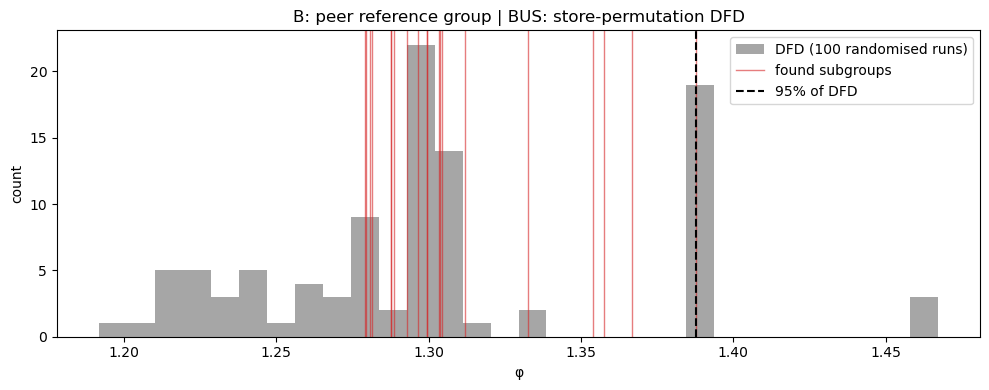

In [79]:
# Why not Bart's swap randomisation here?
# Swap randomisation shuffles distances, so it also destroys the fact that departments
# of the SAME store resemble each other (shared shocks: local events, remodels, growth).
# Our descriptors are store-level, so every subgroup is a union of whole stores, and
# ANY union of 2–3 stores already gets a decent phi.
# Fairer null, in the same spirit as Bart's DFD: keep the target as it is, and give every
# store the descriptor row of a randomly chosen other store. Then rerun the whole search
# and keep the best phi. That answers: "do these ATTRIBUTES pick out unusual stores
# better than random store groupings would?"
# The target doesn't change, so one phi (and its cache) is reused for every permutation.

def permute_descriptors_by_store(A_sub, stores_sub, rng):
    store_ids = np.unique(stores_sub)
    first_row = {s: np.flatnonzero(stores_sub == s)[0] for s in store_ids}
    donor = dict(zip(store_ids, rng.permutation(store_ids)))
    return np.stack([A_sub[first_row[donor[s]]] for s in stores_sub])


def store_permutation_dfd(search, A_sub, stores_sub, phi, nu=NU, seed=SEED):
    rng = np.random.default_rng(seed)
    dfd = []
    for _ in range(nu):
        top, _ = search(permute_descriptors_by_store(A_sub, stores_sub, rng), phi)
        dfd.append(top[0][0] if top else -np.inf)
    return np.array(dfd)


local_dfd = {}
for (setup, method), (top, stats, phi) in local_runs.items():
    A_sub, stores_sub, _, _ = local_setups[setup]
    start = time.time()
    search = beam_search if method == "BS" else bottom_up_search
    local_dfd[(setup, method)] = store_permutation_dfd(search, A_sub, stores_sub, phi)
    print(f"{setup} | {method}: DFD done in {time.time() - start:.0f}s")
    display(local_results_table(top, phi, stores_sub, local_dfd[(setup, method)]).head(10))
    plot_dfd(local_dfd[(setup, method)], top, f"{setup} | {method}: store-permutation DFD")

## Cost-based local subgroups (Konijn et al. → 143-week sales)
- Records = (Store, Dept), used only as row IDs. Descriptions use store attributes only.
- Reference point = peer-expected sales: what this department would have sold if it had moved
  exactly like the same department in the other stores, scaled to its own first-year level.
- e_i(t) = actual − expected, in $ per week. This is the continuous, 143-dim version of Konijn's c·t.
- M1 = excess $ (MVPCD analogue), M2 = relative excess $ (Relative CWTPD analogue, main measure),
  M3 = φ_cluster on the relative deviation curves (Bart, for timing patterns).
- Searches compared: BS (Alg. 1), BUS with α-matrix mini-clusters (§4.3.2), and the BUS → BS hybrid.
- Significance: store-level permutation DFD, as in cell 32.

In [80]:
from collections import Counter

# Reference point
BASE_WEEKS = 52          # first year = one full season cycle, used to set each record's normal level
MIN_BASE_LEVEL = 500     # $/week. Smaller departments give huge % swings from tiny $ changes
MIN_PEERS = 5            # need at least 5 peer records to build a peer index
PEER_KEY = ["Dept"]      # peers = same department. ["Dept", "Type"] = same dept AND same store type
                         # (but then Type stops being useful in descriptions, since peers already share it)

# Search constraints
MIN_COV_M = 0.05         # at least ~2–3 stores
MAX_COV_M = 0.50         # M2 is symmetric (S and the rest mirror each other), so cap at half
POOL_SIZE = 30           # hybrid: number of conditions BS may use
U_PAIRS = U              # number of mini-clusters (200, as in Bart §6.3.1)
NU_M = 100               # permutation runs for the DFD

# Descriptors: store attributes only (Store and Dept are row IDs). Same as cell 27.
local_descriptor_cols = ["Type"] + category_columns
A_local = records[local_descriptor_cols].to_numpy(dtype=object)

def describe_local(desc):
    return " AND ".join(f"{local_descriptor_cols[j]} = {v}" for j, v in desc)

In [81]:
# S[i, t] = raw dollar sales of record i in week t (sales_raw comes from cell 18)
S = sales_raw.to_numpy()
level = S[:, :BASE_WEEKS].mean(axis=1)                 # c in Konijn: normal $/week for this record

peer_key = records[PEER_KEY].astype(str).agg("|".join, axis=1).to_numpy()
ok = level >= MIN_BASE_LEVEL
ok &= pd.Series(ok).groupby(peer_key).transform("sum").to_numpy() >= MIN_PEERS

S_ok, level_ok, key_ok = S[ok], level[ok], peer_key[ok]
A_m = A_local[ok]
stores_m = records["Store"].to_numpy()[ok]

# Leave-one-out peer index: how the same department in the OTHER stores moved,
# relative to their own first-year level (1.0 = their normal week).
#   index_i(t) = (sum of peers' sales in week t) / (sum of peers' normal weekly levels)
group_sales = pd.DataFrame(S_ok).groupby(key_ok).transform("sum").to_numpy()
group_level = pd.Series(level_ok).groupby(key_ok).transform("sum").to_numpy()
peer_index = (group_sales - S_ok) / (group_level - level_ok)[:, None]

# Expected = "if this record had moved exactly like its peers, at its own size".
# Seasonality and department mix are in the peer index, so they cancel out.
expected = level_ok[:, None] * peer_index

excess = S_ok - expected                    # e_i(t), $: the continuous, 143-dim version of c·t
rel_dev = excess / level_ok[:, None]        # r_i(t): the continuous version of t (share of own size)

print(f"Records kept: {ok.sum()} of {len(ok)}")
print(f"Base-year excess per record (0 by construction): max |.| = {np.abs(excess[:, :BASE_WEEKS].sum(1)).max():.4f}")
print("Total excess per record over all weeks ($M), 1/50/99th percentile:",
      np.percentile(excess.sum(1) / 1e6, [1, 50, 99]).round(3))

Records kept: 2566 of 2733
Base-year excess per record (0 by construction): max |.| = 0.0000
Total excess per record over all weeks ($M), 1/50/99th percentile: [-0.854  0.003  0.694]



# other stuff

### 390821/143 = 2700ish records. 143 is the high dim data.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from itertools import combinations
from sklearn.metrics import pairwise_distances

np.random.seed(42)

In [ ]:
# -----------------------------------------------------------
# SETTINGS
# -----------------------------------------------------------
n_stores = 10
n_depts = 10
n_weeks = 52                 # Change to 143 for your actual setup
dates = pd.date_range("2010-02-05", periods=n_weeks, freq="W-FRI")

rows = []

for store in range(1, n_stores + 1):
    for dept in range(1, n_depts + 1):

        # Static descriptors: same for every weekly row of this Store-Dept series
        store_type = np.random.choice(["A", "B", "C"], p=[0.4, 0.4, 0.2])
        size_category = np.random.choice(["small", "medium", "large"])
        
        temperature_mean_category = np.random.choice(["low", "medium", "high"])
        fuel_price_mean_category = np.random.choice(["low", "medium", "high"])
        cpi_mean_category = np.random.choice(["low", "medium", "high"])
        unemployment_mean_category = np.random.choice(["low", "medium", "high"])
        
        temperature_slope_category = np.random.choice(["low", "medium", "high"])
        fuel_price_slope_category = np.random.choice(["low", "medium", "high"])
        cpi_slope_category = np.random.choice(["low", "medium", "high"])
        unemployment_slope_category = np.random.choice(["low", "medium", "high"])

        # Give each Store-Dept series a general profile
        baseline = np.random.normal(0, 0.4)
        trend = np.random.normal(0, 0.015)
        noise_scale = np.random.uniform(0.15, 0.40)

        # Make a deliberately interesting hidden pattern:
        # Type A + large stores have a similar increasing seasonal pattern.
        if store_type == "A" and size_category == "large":
            baseline = 0.5
            trend = 0.035
            noise_scale = 0.15

        # Generate weekly sales values for this ONE Store-Dept time series
        for t, date in enumerate(dates):
            seasonal_component = 0.7 * np.sin(2 * np.pi * t / 13)
            sales = (
                baseline
                + trend * t
                + seasonal_component
                + np.random.normal(0, noise_scale)
            )

            rows.append({
                "Store": store,
                "Dept": dept,
                "Type": store_type,
                "Temperature_mean_category": temperature_mean_category,
                "Fuel_Price_mean_category": fuel_price_mean_category,
                "CPI_mean_category": cpi_mean_category,
                "Unemployment_mean_category": unemployment_mean_category,
                "Temperature_slope_category": temperature_slope_category,
                "Fuel_Price_slope_category": fuel_price_slope_category,
                "CPI_slope_category": cpi_slope_category,
                "Unemployment_slope_category": unemployment_slope_category,
                "Size_category": size_category,
                "Date": date,
                "Standardised_Weekly_Sales": sales
            })

raw_df = pd.DataFrame(rows)


# Export DataFrame to a CSV file
raw_df.to_csv("synthetic_retail_data.csv", index=False)

print(raw_df.shape)
raw_df.head(10)


(57200, 14)


,Store,Dept,Type,Temperature_mean_category,Fuel_Price_mean_category,CPI_mean_category,Unemployment_mean_category,Temperature_slope_category,Fuel_Price_slope_category,CPI_slope_category,Unemployment_slope_category,Size_category,Date,Standardised_Weekly_Sales
0,1,1,B,low,medium,low,high,high,medium,low,medium,large,2010-02-05,-0.199962
1,1,1,B,low,medium,low,high,high,medium,low,medium,large,2010-02-12,0.042958
2,1,1,B,low,medium,low,high,high,medium,low,medium,large,2010-02-19,0.311661
3,1,1,B,low,medium,low,high,high,medium,low,medium,large,2010-02-26,0.812739
4,1,1,B,low,medium,low,high,high,medium,low,medium,large,2010-03-05,0.629748
5,1,1,B,low,medium,low,high,high,medium,low,medium,large,2010-03-12,0.653996
6,1,1,B,low,medium,low,high,high,medium,low,medium,large,2010-03-19,0.413126
7,1,1,B,low,medium,low,high,high,medium,low,medium,large,2010-03-26,-0.366709
8,1,1,B,low,medium,low,high,high,medium,low,medium,large,2010-04-02,-0.505016
9,1,1,B,low,medium,low,high,high,medium,low,medium,large,2010-04-09,-0.762309


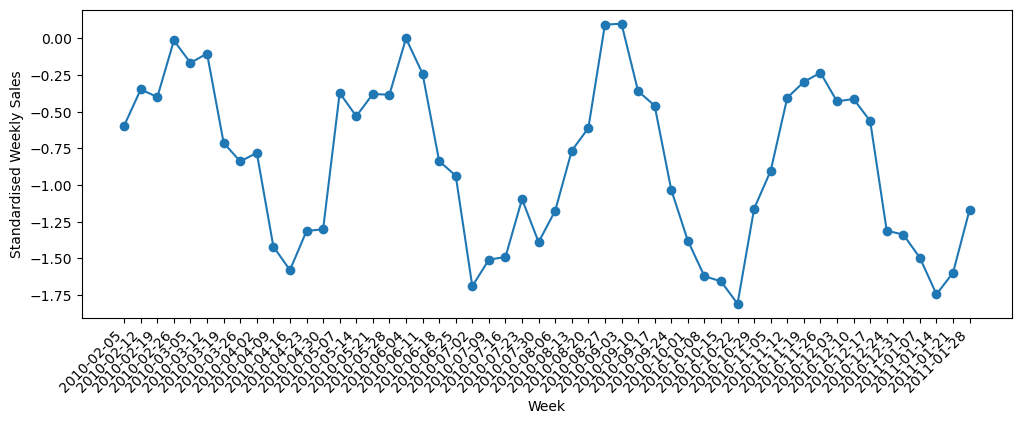

In [17]:
# Export DataFrame to a CSV file
raw_df = pd.read_csv("synthetic_retail_data.csv")

example_store = 1
example_dept = 1

one_series = raw_df[
    (raw_df["Store"] == example_store) &
    (raw_df["Dept"] == example_dept)
].copy()

plt.figure(figsize=(12, 4))

plt.plot(
    one_series["Date"],
    one_series["Standardised_Weekly_Sales"],
    marker="o",
    linewidth=1.5
)

#"One Target Time Series: Store {example_store}, Dept {example_dept}")
plt.xlabel("Week")
plt.ylabel("Standardised Weekly Sales")
plt.xticks(rotation=45, ha='right')  # Rotates labels 45 degrees
plt.show()


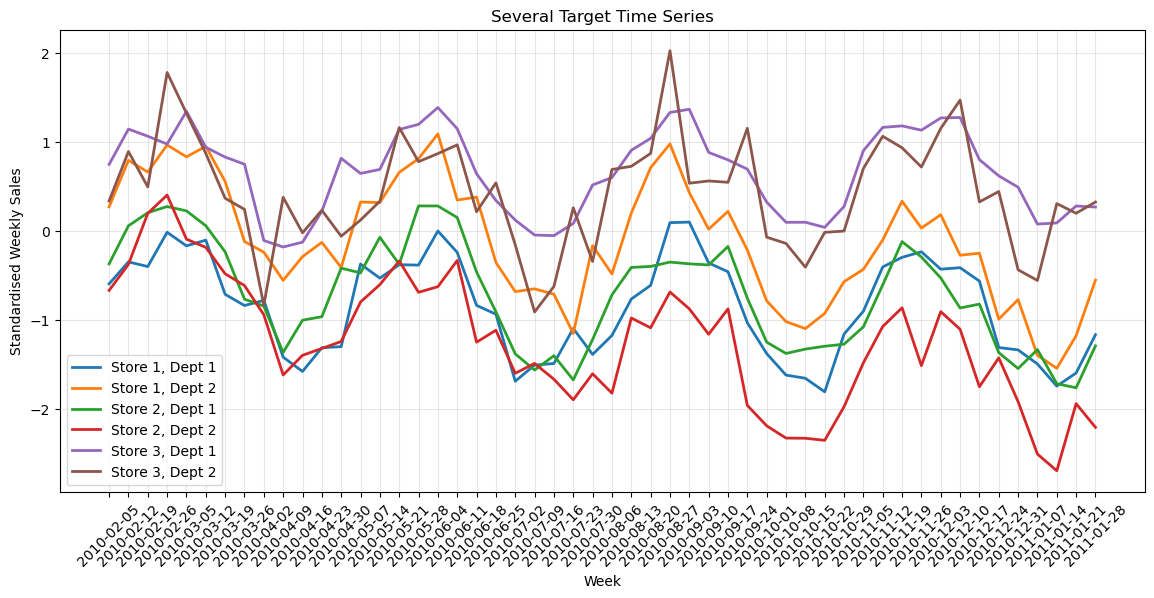

In [18]:
selected_pairs = [
    (1, 1),
    (1, 2),
    (2, 1),
    (2, 2),
    (3, 1),
    (3, 2)
]

plt.figure(figsize=(14, 6))

for store, dept in selected_pairs:
    temp = raw_df[
        (raw_df["Store"] == store) &
        (raw_df["Dept"] == dept)
    ]
    
    plt.plot(
        temp["Date"],
        temp["Standardised_Weekly_Sales"],
        linewidth=2,
        label=f"Store {store}, Dept {dept}"
    )

plt.title("Several Target Time Series")
plt.xlabel("Week")
plt.ylabel("Standardised Weekly Sales")
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

In [ ]:
target_column = "Standardised_Weekly_Sales"

descriptor_columns = [
    "Store",
    "Dept",
    "Type",
    "Temperature_mean_category",
    "Fuel_Price_mean_category",
    "CPI_mean_category",
    "Unemployment_mean_category",
    "Temperature_slope_category",
    "Fuel_Price_slope_category",
    "CPI_slope_category",
    "Unemployment_slope_category",
    "Size_category"
]

identifier_columns = [
    "Store",
    "Dept"
]

print("TARGET:")
print(target_column)

print("\nTIME INDEX:")
print("Date")

print("\nDESCRIPTORS:")
for c in descriptor_columns:
    print("-", c)

print("\nOBJECT IDENTIFIER:")
print("(Store, Dept)") # this shudnt be a descriptor otherwise dept 55 is always gonna be freaking higher and stuff...

TARGET:
Standardised_Weekly_Sales

TIME INDEX:
Date

DESCRIPTORS:
- Store
- Dept
- Type
- Temperature_mean_category
- Fuel_Price_mean_category
- CPI_mean_category
- Unemployment_mean_category
- Temperature_slope_category
- Fuel_Price_slope_category
- CPI_slope_category
- Unemployment_slope_category
- Size_category

OBJECT IDENTIFIER:
(Store, Dept)
